# AI Bee Pollination Agent

A bee collects nectar from a garden while managing its energy and returning safely to the hive. This notebook demonstrates the project algorithms and compares their results.

## Project requirements checklist
- [ ] Use UCS and A* to find routes.
- [ ] Use Q-Learning to choose flowers.
- [ ] Use Hill Climbing and a Genetic Algorithm to optimize flower order.
- [ ] Show a garden with nectar flowers, obstacles, and a hive.
- [ ] Show optimization and learning curves.
- [ ] Compare Search-Based, Learning-Based, and Optimized strategies by nectar, distance, energy, hive returns, and execution time.

## Setup
This part imports the garden, search, strategy, and plotting functions used below.
The imports connect the notebook to the existing project code without changing it.
The plotting setup lets figures appear directly in the notebook.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from environment.garden import BeeGarden
from search.ucs import uniform_cost_search
from search.astar import a_star_search, build_distance_matrix
from evaluation.search_based import search_based_strategy
from optimization import hill_climbing_strategy, genetic_algorithm_strategy
from learning.q_learning import q_learning_strategy, plot_learning_curve
from evaluation.compare import compare_strategies
from evaluation.metrics import compute_metrics, check_result

## The garden
This part creates the required 15-by-15 garden with `BeeGarden` and prints its rules.
The energy, collection cost, flower count, and obstacle count define the simulation limits.
These rules are shared by the routing, learning, and optimization strategies.

In [2]:
env = BeeGarden(15, 15, n_flowers=10, seed=0)

print(f"Garden size: {env.width} x {env.height}")
print(f"Hive position: {env.hive}")
print(f"Energy limit: {env.energy_limit}")
print(f"Collect cost: {env.collect_cost}")
print(f"Number of flowers: {len(env.flowers)}")
print(f"Number of obstacles: {len(env.obstacles)}")

Garden size: 15 x 15
Hive position: (0, 0)
Energy limit: 60
Collect cost: 2
Number of flowers: 10
Number of obstacles: 38


### Garden drawing helper
This part defines `draw_garden`, a notebook helper for viewing the map and routes.
It marks the hive, obstacles, and nectar values, with the route drawn over the grid.
The inverted vertical axis keeps the garden coordinates consistent with the project.

In [3]:
def draw_garden(env, route=None, title=""):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(-0.5, env.width - 0.5)
    ax.set_ylim(env.height - 0.5, -0.5)
    ax.set_xticks(range(env.width))
    ax.set_yticks(range(env.height))
    ax.set_xticks(np.arange(-0.5, env.width, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, env.height, 1), minor=True)
    ax.grid(which="minor", color="lightgray", linewidth=0.6)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_aspect("equal")
    ax.set_xlabel("x position")
    ax.set_ylabel("y position")
    ax.set_title(title or "Bee Garden")

    if env.obstacles:
        obstacle_x, obstacle_y = zip(*env.obstacles)
        ax.scatter(obstacle_x, obstacle_y, marker="s", color="dimgray", label="Obstacle", zorder=2)

    flower_positions = list(env.flowers)
    nectar_values = [env.flowers[pos] for pos in flower_positions]
    flower_scatter = ax.scatter(
        [pos[0] for pos in flower_positions],
        [pos[1] for pos in flower_positions],
        s=[90 + value * 7 for value in nectar_values],
        c=nectar_values,
        cmap="YlOrRd",
        vmin=min(nectar_values),
        vmax=max(nectar_values),
        edgecolors="black",
        label="Flower",
        zorder=3,
    )
    for (x, y), nectar in env.flowers.items():
        ax.text(x, y, str(nectar), ha="center", va="center", fontsize=8, zorder=4)
    fig.colorbar(flower_scatter, ax=ax, label="Nectar value")

    ax.scatter(
        [env.hive[0]], [env.hive[1]], marker="*", s=280,
        color="gold", edgecolors="black", label="Hive", zorder=5,
    )
    if route:
        ax.plot(
            [pos[0] for pos in route],
            [pos[1] for pos in route],
            color="royalblue", linewidth=2, marker=".",
            label="Route", zorder=1,
        )
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

### Show the empty garden
This part calls `draw_garden` to show the garden before the bee travels.
The empty-map view makes the hive, flowers, obstacles, and nectar values easy to inspect.
It establishes the same visual setting used by the strategy route plots.

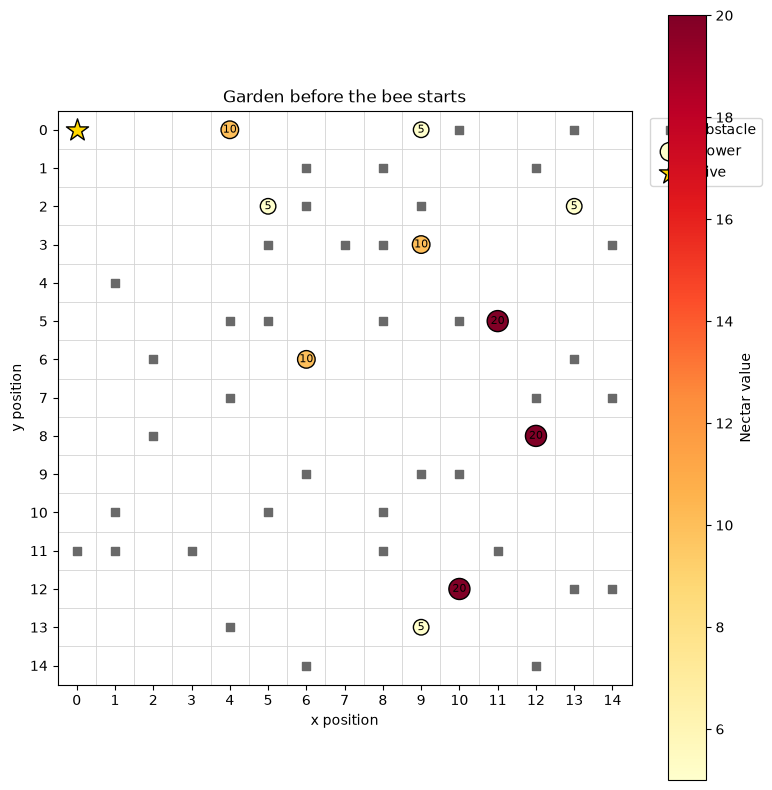

In [4]:
draw_garden(env, title="Garden before the bee starts")

This part calls `build_distance_matrix` to prepare shortest paths between the hive and flowers.
The matrix allows the strategies to reuse route costs instead of searching repeatedly.
It supports a fair and efficient comparison of the project strategies.

In [5]:
matrix = build_distance_matrix(env)
print(f"Distance matrix entries: {len(matrix)}")

Distance matrix entries: 121


## Search algorithms
This part calls `uniform_cost_search` and `a_star_search` from the hive to one flower.
Both paths and costs are printed, and the optimal costs are checked for equality.
Comparing these searches verifies the required route-finding algorithms.

In [6]:
target_flower = next(iter(env.flowers))
ucs_path, ucs_cost = uniform_cost_search(env, env.hive, target_flower)
astar_path, astar_cost = a_star_search(env, env.hive, target_flower)

print(f"Target flower: {target_flower}")
print(f"UCS path: {ucs_path}")
print(f"UCS cost: {ucs_cost}")
print(f"A* path: {astar_path}")
print(f"A* cost: {astar_cost}")
assert ucs_cost == astar_cost, "UCS and A* should find equal optimal costs."
print("UCS and A* costs are equal.")

Target flower: (9, 0)
UCS path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0)]
UCS cost: 9
A* path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0)]
A* cost: 9
UCS and A* costs are equal.


This part calls `draw_garden` with the A* route to the selected flower.
The visualized path connects the hive to the target while avoiding obstacles.
It shows how A* supplies a route for the bee.

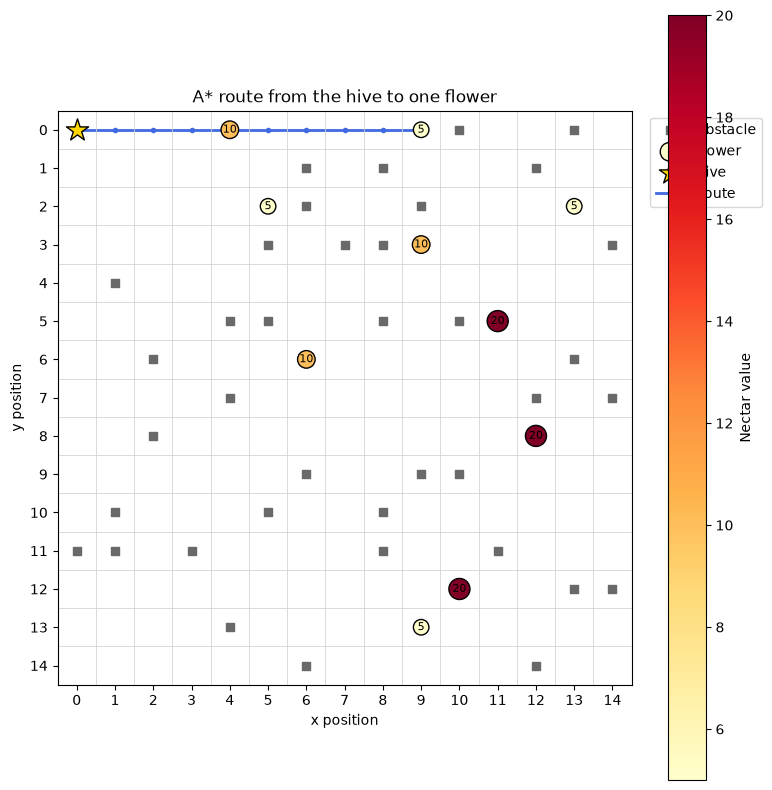

In [7]:
draw_garden(env, route=astar_path, title="A* route from the hive to one flower")

## Search-Based strategy
This part calls `search_based_strategy` with the shared distance matrix.
The printed summary reports nectar, travel, energy, flowers visited, and hive return.
These measures describe the Search-Based strategy's safe, nearest-flower behavior.

In [8]:
search_result = search_based_strategy(env, matrix=matrix)
print(f"Nectar collected: {search_result['nectar']}")
print(f"Travel distance: {search_result['distance']}")
print(f"Energy used: {search_result['energy_used']}")
print(f"Visited flowers: {search_result['visited']}")
print(f"Returned to hive: {search_result['returned']}")

Nectar collected: 80
Travel distance: 46
Energy used: 60
Visited flowers: [(4, 0), (5, 2), (9, 0), (9, 3), (11, 5), (12, 8), (6, 6)]
Returned to hive: True


This part calls `draw_garden` with the Search-Based strategy's complete route.
The route shows which flowers were selected and how the bee returned to the hive.
It makes the strategy's decisions visible on the garden grid.

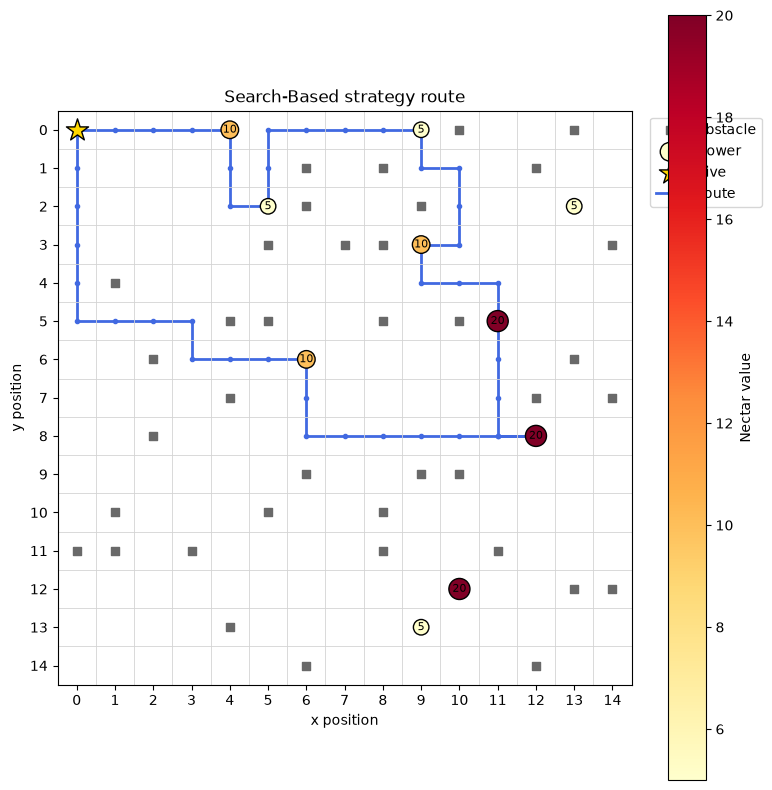

In [9]:
draw_garden(env, route=search_result["route"], title="Search-Based strategy route")

## Optimization
This part calls `hill_climbing_strategy` to improve the order of flower visits.
Its summary uses the same nectar, distance, energy, visited-flower, and return measures.
Hill Climbing is one required optimization method for the project.

In [10]:
hill_result = hill_climbing_strategy(env, matrix=matrix)
print(f"Nectar collected: {hill_result['nectar']}")
print(f"Travel distance: {hill_result['distance']}")
print(f"Energy used: {hill_result['energy_used']}")
print(f"Visited flowers: {hill_result['visited']}")
print(f"Returned to hive: {hill_result['returned']}")

Nectar collected: 85
Travel distance: 48
Energy used: 60
Visited flowers: [(9, 0), (11, 5), (12, 8), (10, 12), (6, 6), (4, 0)]
Returned to hive: True


This part calls `draw_garden` with the Hill Climbing route.
The map shows the optimized order as a walk through the flower locations.
It connects the optimization result to the bee's actual travel.

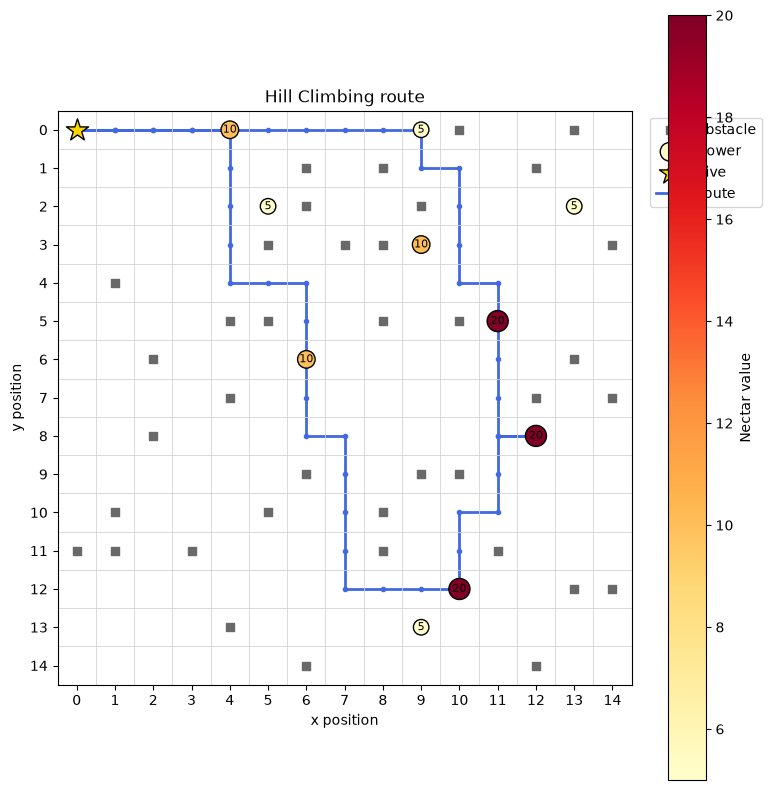

In [11]:
draw_garden(env, route=hill_result["route"], title="Hill Climbing route")

This part calls `genetic_algorithm_strategy` to optimize the flower-visit order.
The printed summary uses the same performance and safety measures as the other strategies.
The Genetic Algorithm provides a second required optimization approach.

In [12]:
genetic_result = genetic_algorithm_strategy(env, matrix=matrix)
print(f"Nectar collected: {genetic_result['nectar']}")
print(f"Travel distance: {genetic_result['distance']}")
print(f"Energy used: {genetic_result['energy_used']}")
print(f"Visited flowers: {genetic_result['visited']}")
print(f"Returned to hive: {genetic_result['returned']}")

Nectar collected: 85
Travel distance: 48
Energy used: 60
Visited flowers: [(6, 6), (10, 12), (12, 8), (11, 5), (9, 0), (4, 0)]
Returned to hive: True


This part calls `draw_garden` with the Genetic Algorithm route.
The plot shows the visit order and the return trip on the obstacle-filled grid.
It helps compare optimized routes with the Search-Based route.

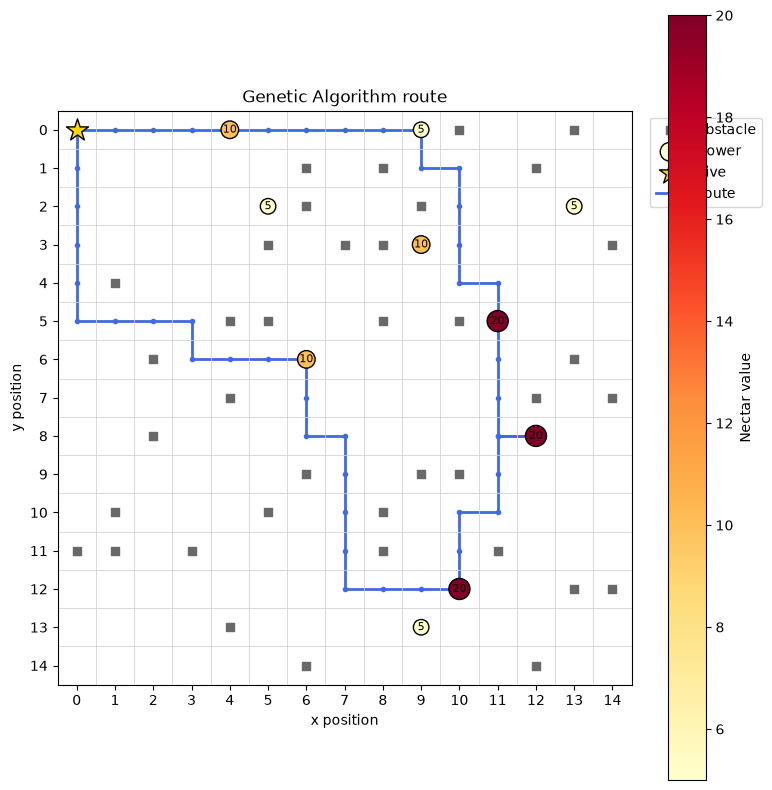

In [13]:
draw_garden(env, route=genetic_result["route"], title="Genetic Algorithm route")

This part plots the histories from `hill_climbing_strategy` and `genetic_algorithm_strategy`.
The curves show how each optimizer's best fitness changes during its search.
Convergence curves help explain the project requirement to optimize visit order.

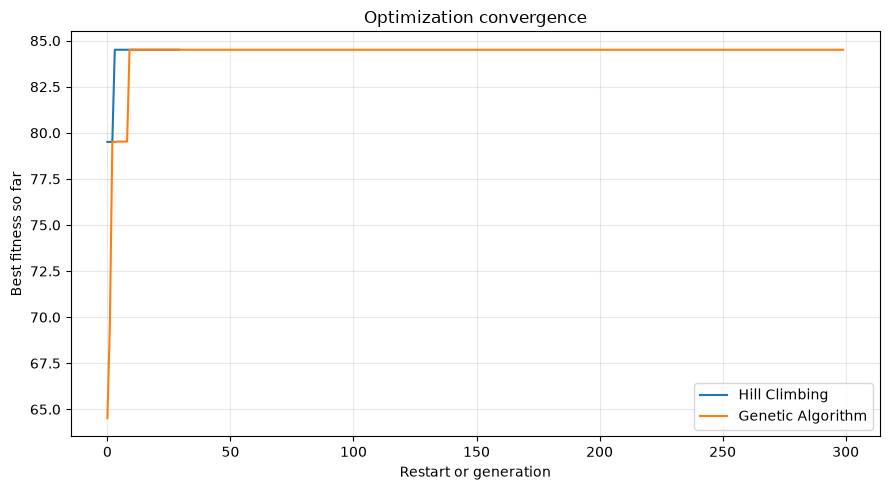

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(hill_result["history"], label="Hill Climbing")
plt.plot(genetic_result["history"], label="Genetic Algorithm")
plt.title("Optimization convergence")
plt.xlabel("Restart or generation")
plt.ylabel("Best fitness so far")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Learning
This part calls `q_learning_strategy` to learn which flowers to visit under the energy limit.
Its summary reports the same route, reward, energy, and return outcomes as other methods.
Q-Learning supplies the Learning-Based strategy required by the project.

In [15]:
q_learning_result = q_learning_strategy(env, matrix=matrix)
print(f"Nectar collected: {q_learning_result['nectar']}")
print(f"Travel distance: {q_learning_result['distance']}")
print(f"Energy used: {q_learning_result['energy_used']}")
print(f"Visited flowers: {q_learning_result['visited']}")
print(f"Returned to hive: {q_learning_result['returned']}")

Nectar collected: 80
Travel distance: 50
Energy used: 60
Visited flowers: [(10, 12), (12, 8), (11, 5), (9, 3), (4, 0)]
Returned to hive: True


This part calls `draw_garden` with the learned Q-Learning route.
The route shows the final trip selected after the training episodes.
It lets us inspect what the learning strategy actually did in the garden.

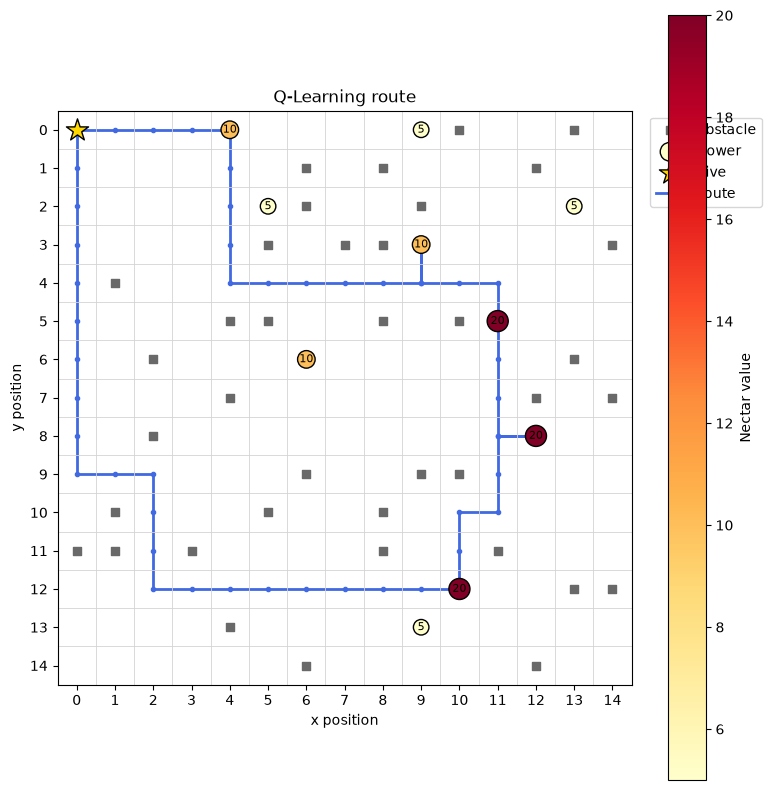

In [16]:
draw_garden(env, route=q_learning_result["route"], title="Q-Learning route")

This part calls `compute_metrics` and `check_result` for the four strategy results.
The metric values summarize performance, while rule checks confirm safe valid routes.
This check supports a reliable comparison of the project strategies.

In [17]:
strategy_results = [
    ("Search-Based", search_result),
    ("Hill Climbing", hill_result),
    ("Genetic Algorithm", genetic_result),
    ("Q-Learning", q_learning_result),
]
for strategy_name, result in strategy_results:
    problems = check_result(env, result)
    print(f"{strategy_name}: {compute_metrics(result)}")
    print(f"Rule check: {'PASS' if not problems else '; '.join(problems)}")
    if problems:
        raise ValueError(f"Invalid result from {strategy_name}: {problems}")

Search-Based: {'Total Nectar Collected': 80, 'Travel Distance': 46, 'Energy Consumption': 60, 'Successful Hive Returns': 1, 'Execution Time (s)': 0.0001}
Rule check: PASS
Hill Climbing: {'Total Nectar Collected': 85, 'Travel Distance': 48, 'Energy Consumption': 60, 'Successful Hive Returns': 1, 'Execution Time (s)': 0.0653}
Rule check: PASS
Genetic Algorithm: {'Total Nectar Collected': 85, 'Travel Distance': 48, 'Energy Consumption': 60, 'Successful Hive Returns': 1, 'Execution Time (s)': 0.5938}
Rule check: PASS
Q-Learning: {'Total Nectar Collected': 80, 'Travel Distance': 50, 'Energy Consumption': 60, 'Successful Hive Returns': 1, 'Execution Time (s)': 0.4102}
Rule check: PASS


This part calls `plot_learning_curve` with the Q-Learning episode history.
The saved figure and displayed moving average show how rewards change during training.
A learning curve is required to assess whether the bee improves through experience.

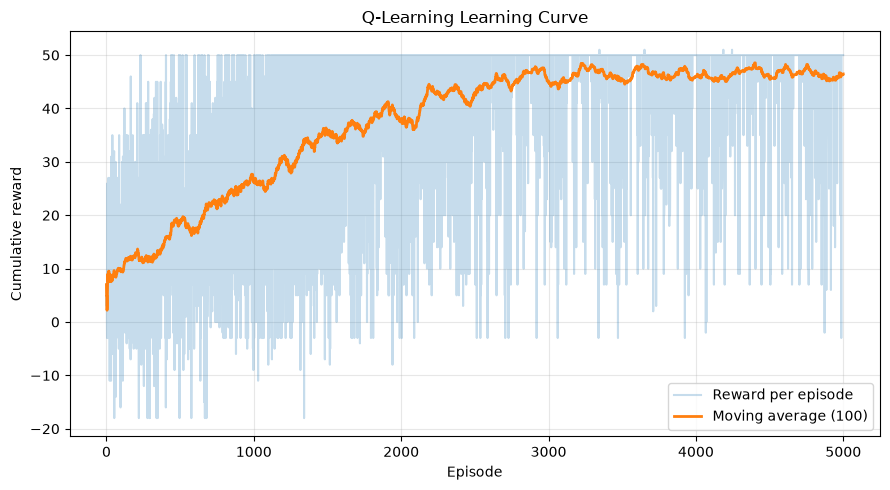

In [18]:
plot_learning_curve(
    q_learning_result["history"],
    path="results/learning_curve.png",
    show=True,
)

## Comparison
This part calls `compare_strategies` on three maps with CSV saving disabled.
The function returns per-map results, average metrics, and each full strategy result.
The comparison covers Search-Based, Learning-Based, and Optimized strategies.

In [19]:
per_map, summary, comparison_results = compare_strategies(
    seeds=(0, 1, 2),
    size=15,
    n_flowers=10,
    save_csv=False,
)
print(f"Per-map rows: {len(per_map)}")
print(f"Strategy summaries: {len(summary)}")

Per-map rows: 12
Strategy summaries: 4


This part displays the `summary` DataFrame returned by `compare_strategies`.
Its averages and return counts let us compare all five required project metrics.
Use this table to identify which strategy performed best for each measure.

In [20]:
summary

,Type,Strategy,Total Nectar Collected,Travel Distance,Energy Consumption,Successful Hive Returns,Execution Time (s),Runs
0,Search-Based,A* + Nearest Flower,78.33,42.67,56.00,3,0.00,3
1,Optimized,Hill Climbing,88.33,44.67,58.00,3,0.10,3
2,Optimized,Genetic Algorithm,88.33,45.33,58.67,3,0.69,3
3,Learning-Based,Q-Learning,83.33,47.33,59.33,3,0.44,3


This part uses `per_map.groupby` to average nectar collected for each strategy.
The bar chart makes the three-map nectar comparison easy to read.
A higher bar means more nectar was collected on average.

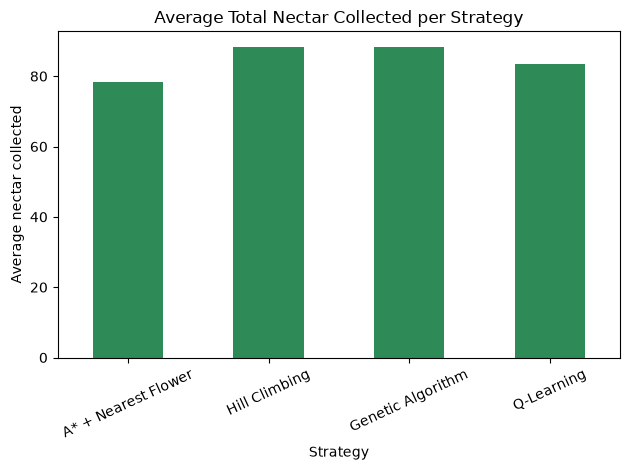

In [21]:
nectar_average = per_map.groupby("Strategy", sort=False)["Total Nectar Collected"].mean()
nectar_average.plot(kind="bar", color="seagreen", rot=25)
plt.title("Average Total Nectar Collected per Strategy")
plt.xlabel("Strategy")
plt.ylabel("Average nectar collected")
plt.tight_layout()
plt.show()

This part uses `per_map.groupby` to average execution time for each strategy.
The chart compares the time spent by each method across the same three maps.
A shorter bar means the strategy ran faster in this comparison.

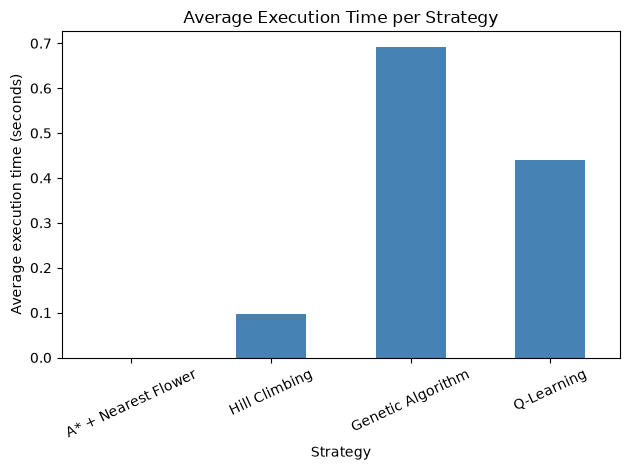

In [22]:
time_average = per_map.groupby("Strategy", sort=False)["Execution Time (s)"].mean()
time_average.plot(kind="bar", color="steelblue", rot=25)
plt.title("Average Execution Time per Strategy")
plt.xlabel("Strategy")
plt.ylabel("Average execution time (seconds)")
plt.tight_layout()
plt.show()

## Conclusion

- Name the nectar leader by finding the strategy with the largest **Total Nectar Collected** average.
- Name the fastest strategy by finding the smallest **Execution Time (s)** average.
- Check **Travel Distance** and **Energy Consumption** to understand the cost of each route.
- **Successful Hive Returns** shows whether the strategy brought the bee back safely on the maps.
- Optimization may collect more by improving visit order, while Search-Based methods can be faster because they do not train; Q-Learning time includes training.

Fill in the final numbers after running